In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt
import sys
import powerlaw
import matplotlib.lines as mlines

%pip install powerlaw


from cycler import cycler

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

colors = plt.get_cmap("viridis")(np.linspace(0, 1, 10))
plt.rcParams["axes.prop_cycle"] = cycler(color=colors)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
def create_network(N, K):
    p_connect = K / N #probability that two elements are connected

    neighbours = [[] for _ in range(N)]

    for i in range(N):
        for j in range(i+1, N): 
            if random.random() < p_connect:
                neighbours[i].append(j)
                neighbours[j].append(i) #to obtain an undirected network
    return neighbours

In [4]:
def init_p_values(neighbours, sigma, K):
    p_max = (2 * sigma / K)

    p_values = [[] for _ in range(len(neighbours))]
    edge_values = {}

    for i, nb in enumerate(neighbours):
        for j in nb:
            edge = tuple(sorted((i,j))) #ensures that undirected edges are not stored twice

            if edge not in edge_values:
                edge_values[edge] = random.uniform (0, p_max)

            p_values[i].append(edge_values[edge])

    return p_values #indicates 'strength' of connection, i.e. likelihood that this specific active unit activates this specific neighbour

In [5]:
def init_states(N, initial_active):
    states = [0] * N
    for i in random.sample(range(N), initial_active):
        states[i] = 1
    return states

In [6]:
def external_stimulation(N, r):
    dt=1
    p_ext = 1 - np.exp(-r * dt) #in the K&C paper they call it lambda
    stimulated = []
    for i in range(N):
        if random.random() < p_ext:
            stimulated.append(i)
    return stimulated
    
    
#at every time step, every node can be activated by an external stimulus, probability modelled by a Poisson process


[10, 10, 8, 10, 15, 7, 12, 9, 9, 8, 15, 11, 13, 13, 15, 5, 8, 9, 17, 9]


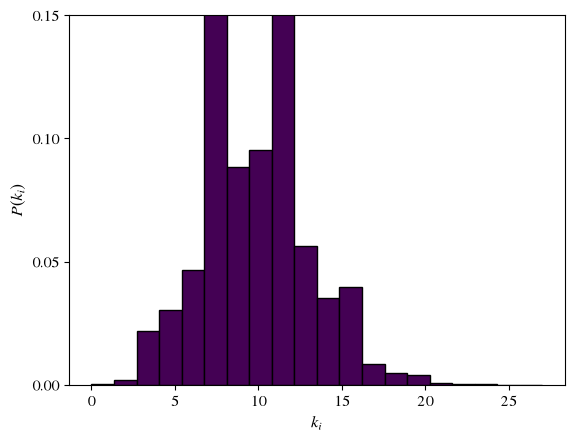

average degree K: 9.9162
[9, 15, 6, 9, 10, 11, 13, 11, 12, 13, 6, 10, 11, 8, 8, 15, 9, 7, 11, 12]


In [ ]:
#inset plot of figure 1A to check if K is correct

neighbours = create_network(10000, 10)

degrees = [len(nb) for nb in neighbours]
print(degrees[:20])

plt.hist(degrees, bins=20, edgecolor='black', density=True)
plt.xlabel(r"$k_i$")
plt.ylabel(r"$P(k_i)$")
plt.yticks(np.arange(0, 0.16, 0.05))
plt.ylim(0, 0.15)
plt.savefig("mein_plot.pdf") 
plt.show()


avg_degree = np.mean([len(nbs) for nbs in neighbours])
print("average degree K:", avg_degree)



neighbours = create_network(10000, 10)

degrees = [len(nb) for nb in neighbours]
print(degrees[:20])


average degree K: 9.9412


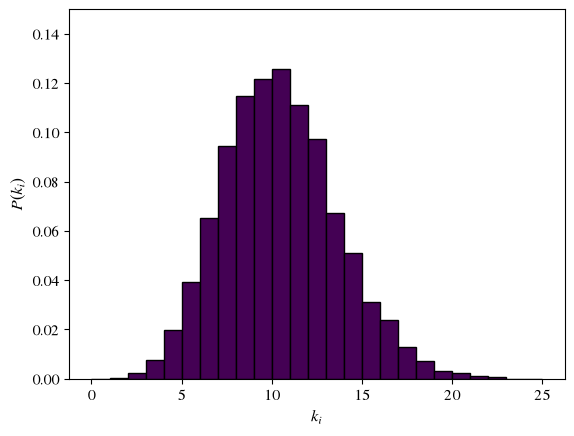

In [ ]:
#degree distribution with corrected bin width to account for discrete values

n_runs = 1 #multiple runs possible if necessary
all_histograms = []

bins = np.arange(0, 26, 1)

for i in range(n_runs):
    neighbours = create_network(10000, 10)
    degrees = [len(nb) for nb in neighbours]
    avg_degree = np.mean(degrees)
    print("average degree K:", avg_degree)

    hist, bin_edges = np.histogram(
        degrees,
        bins=bins,
        density=True
    )

    all_histograms.append(hist)

mean_histogram = np.mean(all_histograms, axis=0)

plt.bar(
    bins[:-1],
    mean_histogram,
    width=1,
    edgecolor='black',
    align='edge'
)

plt.xlabel(r"$k_i$")
plt.ylabel(r"$P(k_i)$")
plt.ylim(0, 0.15)

plt.savefig("Figure_1_new.pdf")
plt.show()

In [ ]:
def update_states(prev_states, neighbours, p_values, num_states, N, r=0): #r=0 means no external stimulation
    N = len(prev_states)
    new_states = prev_states.copy()
    
    for i in range(N):
        if prev_states[i] >= 1: #resting states are not affected
            if prev_states[i] < num_states - 1:
                new_states[i] += 1
            else:
                new_states[i] = 0 #when n-1 is reached -> back to resting

    #resting
    for i in range(N):
        if prev_states[i] == 1:
            for idx, j in enumerate(neighbours[i]):
                if prev_states[j] == 0: #can only be excited when in resting state
                    if random.random() < p_values[i][idx]:
                        new_states[j] = 1

    #external stimulation
    stimulated = external_stimulation(N, r) #rate r is proportional to stimulus level S
    for i in stimulated:
        if new_states[i] == 0: #can only be excited when still in resting state
            new_states[i] = 1
                
    return new_states

In [8]:
def run_simulation(N, K, num_states, initial_active, sigma, timesteps):
    neighbours = create_network(N, K)
    p_values = init_p_values(neighbours, sigma, K)
    states = init_states(N, initial_active)

    activity = []

    for t in range(timesteps):
        active_count = sum(1 for s in states if s == 1)
        activity.append(active_count)
        states = update_states(states, neighbours, p_values, num_states, N)

    return np.array(activity)

In [ ]:
def plot_activity(activity_dict, N):
    plt.figure(figsize=(10,5))

    # collect sigma values from keys like 'sigma=0.95, run=1'
    import re
    sigma_vals = []
    for key in activity_dict.keys():
        m = re.search(r'sigma=([0-9\.]+)', key)
        if m:
            sigma_vals.append(float(m.group(1)))
    unique_sigmas = sorted(set(sigma_vals))

    # choose a color for each sigma group
    cmap = plt.get_cmap('viridis') #uses already defined color palette
    color_map = {
        s: cmap(i / (len(unique_sigmas) - 1))
        for i, s in enumerate(unique_sigmas)
    }

    for label, activity in activity_dict.items():
        m = re.search(r'sigma=([0-9\.]+)', label)
        sigma = float(m.group(1)) if m else None
        color = color_map.get(sigma, 'black')
        density = activity / N
        time = np.arange(len(activity))
        plt.plot(time, density, label=label, color=color, alpha=0.7)

    plt.xlabel("Time (ms)")
    plt.ylabel("Density")
    plt.yscale('log')
    plt.ylim(1e-5, 1e-1)
    #plt.xlim(0, 200)
    plt.grid(True, which='both', alpha=0.7)

    # show a concise legend for sigma groups (one handle per sigma)
    import matplotlib.lines as mlines
    handles = [mlines.Line2D([], [], color=color_map[s], label=f'sigma={s}') for s in unique_sigmas]
    plt.legend(handles=handles)
    plt.savefig("Figure_2.pdf") 
    plt.show()
    


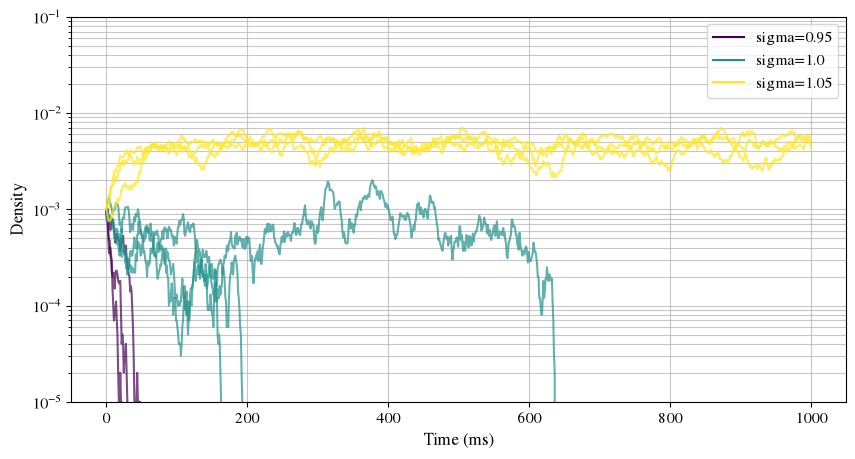

In [ ]:
N = 100000 #as in the K&C paper
num_states = 10
K = 10
initial_active = 100
sigma_values = [0.95, 1, 1.05]
runs_per_sigma = 3
timesteps = 1000

activity_dict = {}

for sigma in sigma_values:
    for run in range(runs_per_sigma):
        activity = run_simulation(N, K, num_states, initial_active, sigma, timesteps)
        key = f"sigma={sigma}, run={run+1}"
        activity_dict[key] = activity

plot_activity(activity_dict, N)

In [ ]:
def run_avalanche_simulation(N, K, num_states, sigma, max_steps, num_avalanches):
    neighbours = create_network(N, K)
    p_values = init_p_values(neighbours, sigma, K)

    all_avalanches = []
    censored = 0
    
    for _ in range(num_avalanches):
        states = init_states(N, initial_active=1)
        avalanche_size = 0
        finished = False

        for t in range(max_steps):
            active_count = sum(1 for s in states if s == 1)

            if active_count == 0:
                finished = True
                break

            avalanche_size += active_count
            states = update_states(states, neighbours, p_values, num_states, N)

        if finished:
            all_avalanches.append(avalanche_size)
        else:
            censored += 1

    return all_avalanches, censored



In [ ]:
import re


def plot_avalanches(avalanche_dict):
    plt.figure(figsize=(8,6))

    #preparation for reference line
    ref_centers = None
    ref_hist = None
    all_sizes = []

    #collect sigma values
    sigma_vals = []
    for key in avalanche_dict.keys():
        m = re.search(r'sigma=([0-9\.]+)', key)
        if m:
            sigma_vals.append(float(m.group(1)))

    unique_sigmas = sorted(set(sigma_vals))

    #one color per sigma
    cmap = plt.get_cmap("viridis")

    if len(unique_sigmas) == 1:
        color_map = {unique_sigmas[0]: cmap(0.5)}
    else:
        color_map = {
            s: cmap(i / (len(unique_sigmas) - 1))
            for i, s in enumerate(unique_sigmas)
        }

    for label, sizes in avalanche_dict.items():
        m = re.search(r'sigma=([0-9\.]+)', label)
        sigma = float(m.group(1))
        color = color_map[sigma]

        sizes = np.array(sizes)
        sizes = sizes[sizes > 0]

        all_sizes.append(sizes)

        bins = np.logspace(np.log10(min(sizes)), np.log10(max(sizes)), 30)
        hist, edges = np.histogram(sizes, bins=bins, density=True)
        centers = np.sqrt(edges[:-1] * edges[1:])

        plt.loglog(centers, hist, 'o', color=color)

        if ref_centers is None:
            ref_centers = centers
            ref_hist = hist

    #reference line S^{-3/2}
    all_sizes = np.concatenate(all_sizes)

    x_ref = np.logspace(np.log10(min(all_sizes)),
                        np.log10(max(all_sizes)), 200)

    mask = ((ref_centers > np.percentile(ref_centers, 30)) &
            (ref_centers < np.percentile(ref_centers, 70)))

    scale = np.mean(ref_hist[mask] /
                    (ref_centers[mask]**(-1.5)))

    y_ref = scale * x_ref**(-1.5)

    plt.loglog(x_ref, y_ref, '--', color='black',
               linewidth=2)

    #layout
    plt.xlabel("Avalanche size $S$")
    plt.ylabel("Probability $P(S)$")
    plt.grid(True, which="both", alpha=0.3)

    #legend
    handles = [
        mlines.Line2D([], [], color=color_map[s], marker='o',
                      linestyle='None', label=f'sigma={s}')
        for s in unique_sigmas
    ]

    handles.append(
        mlines.Line2D([], [], color='black',
                      linestyle='--',
                      label=r'$S^{-3/2}$')
    )

    plt.legend(handles=handles)
    plt.tight_layout()
    plt.savefig("Figure_3.pdf") 
    plt.show()

sigma=0.95: 0/1000 avalanches reached max_steps
sigma=1: 0/1000 avalanches reached max_steps
sigma=1.05: 2/1000 avalanches reached max_steps


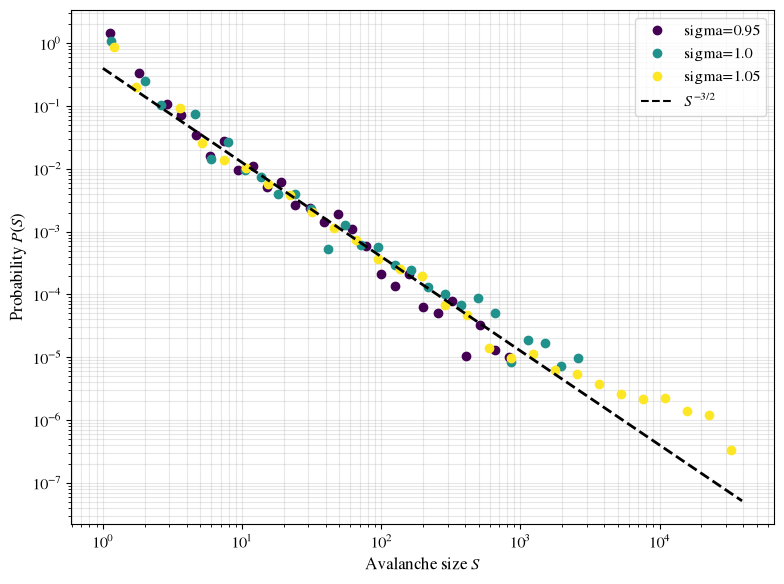

In [ ]:
N = 10000
num_states = 10
K = 10
initial_active = 1
max_steps = 1000
sigma_values = [0.95, 1, 1.05] 
num_avalanches = 1000

avalanche_dict = {}

for sigma in sigma_values:
    sizes, censored = run_avalanche_simulation(N, K, num_states, sigma, max_steps, num_avalanches)
    avalanche_dict[f"sigma={sigma}"] = sizes

    print(f"sigma={sigma}: "f"{censored}/{num_avalanches} avalanches reached max_steps")

plot_avalanches(avalanche_dict)

In [ ]:
def powerlaw_fit(avalanche_dict, sigma):
    data = avalanche_dict[f"sigma={sigma}"]

    fit = powerlaw.Fit(data, discrete=True)

    alpha = fit.power_law.alpha
    xmin = fit.power_law.xmin

    R, p = fit.distribution_compare('power_law', 'truncated_power_law')


    return alpha, xmin, R, p


for sigma in sigma_values:
        alpha, xmin, R, p = powerlaw_fit(avalanche_dict, sigma)
        print(f"\nSigma = {sigma}")
        print(f"alpha: {alpha}")
        print(f"xmin: {xmin}")
        print(f"R: {R}, p: {p}")


Calculating best minimal value for power law fit


Fitting xmin:   0%|          | 0/103 [00:00<?, ?it/s]

Fitting xmin: 100%|██████████| 103/103 [00:00<00:00, 381.69it/s]
c:\Users\Ramona\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')



Sigma = 0.95
alpha: 1.5663481444455551
xmin: 1.0
R: -19.288546213137327, p: 5.26330645733708e-10
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 155/155 [00:00<00:00, 516.85it/s]
c:\Users\Ramona\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')



Sigma = 1
alpha: 1.4761806562265551
xmin: 1.0
R: -12.427630129925927, p: 6.18001760432918e-07
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 176/176 [00:01<00:00, 145.12it/s]



Sigma = 1.05
alpha: 1.437691620797679
xmin: 1.0
R: -2.8336682103517132, p: 0.01728368012089998


c:\Users\Ramona\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')
